# Which recipes bring traffic to the site?

A recipe website features one recipe on its home page each day. When the featured recipe is popular, traffic to the whole site rises by as much as 40%, and with it subscriptions. At the moment the recipe is picked by hand. The product team wants to know two things:

1. Can we predict which recipes will lead to high traffic?
2. Can we be right about "high traffic" at least 80% of the time?

The second goal is a statement about **precision**: of the recipes the model recommends, at least 80% should turn out to be high-traffic. The data is 947 recipes that have already been featured, with their nutritional values, category, servings and whether traffic was high.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
SEED = 42

raw = pd.read_csv("data/recipe_site_traffic.csv")
print(raw.shape)
raw.head()

(947, 8)


,recipe,calories,carbohydrate,sugar,protein,category,servings,high_traffic
0,1,NaN,NaN,NaN,NaN,Pork,6,High
1,2,35.48,38.56,0.66,0.92,Potato,4,High
2,3,914.28,42.68,3.09,2.88,Breakfast,1,NaN
3,4,97.03,30.56,38.63,0.02,Beverages,4,High
4,5,27.05,1.85,0.80,0.53,Beverages,4,NaN


## 1. Validating the data

In [2]:
pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "distinct": raw.nunique()})

,dtype,missing,distinct
recipe,int64,0,947
calories,float64,52,891
carbohydrate,float64,52,835
sugar,float64,52,666
protein,float64,52,772
category,str,0,11
servings,str,0,6
high_traffic,str,373,1


In [3]:
print("servings:", raw["servings"].value_counts().to_dict())
print("high_traffic:", raw["high_traffic"].value_counts(dropna=False).to_dict())
print("duplicate recipe ids:", raw["recipe"].duplicated().sum())

servings: {'4': 389, '6': 197, '2': 183, '1': 175, '4 as a snack': 2, '6 as a snack': 1}
high_traffic: {'High': 574, nan: 373}
duplicate recipe ids: 0


Four things need fixing:

- **`high_traffic`** is either "High" or empty. An empty value means the recipe did not produce high traffic, so it becomes 0.
- **`servings`** is text because three rows read "4 as a snack" or "6 as a snack". The number is extracted.
- **`category`** has eleven values where ten were expected: "Chicken Breast" is a variant of "Chicken" and is merged into it.
- **Nutrition** is missing for 52 recipes, always all four values together. Those rows are kept: the values are imputed inside the modelling pipeline, using training data only.

In [4]:
recipes = raw.copy()
recipes["high_traffic"] = (recipes["high_traffic"] == "High").astype(int)
recipes["servings"] = recipes["servings"].str.extract(r"(\d+)").astype(int)
recipes["category"] = recipes["category"].replace({"Chicken Breast": "Chicken"})

nutrition = ["calories", "carbohydrate", "sugar", "protein"]
print("Rows with missing nutrition:", recipes[nutrition].isna().any(axis=1).sum(),
      "| all four missing together:", recipes[nutrition].isna().all(axis=1).sum())
print(f"Share of recipes with high traffic: {recipes['high_traffic'].mean():.1%}")
recipes.describe().round(2)

Rows with missing nutrition: 52 | all four missing together: 52
Share of recipes with high traffic: 60.6%


,recipe,calories,carbohydrate,sugar,protein,servings,high_traffic
count,947.00,895.00,895.00,895.00,895.00,947.00,947.00
mean,474.00,435.94,35.07,9.05,24.15,3.48,0.61
std,273.52,453.02,43.95,14.68,36.37,1.73,0.49
min,1.00,0.14,0.03,0.01,0.00,1.00,0.00
25%,237.50,110.43,8.38,1.69,3.20,2.00,0.00
50%,474.00,288.55,21.48,4.55,10.80,4.00,1.00
75%,710.50,597.65,44.96,9.80,30.20,4.00,1.00
max,947.00,3633.16,530.42,148.75,363.36,6.00,1.00


About 61% of featured recipes led to high traffic. That sets the bar: picking at random would be right 61% of the time, so the model has to add nineteen points of precision to reach the goal.

## 2. What separates high-traffic recipes?

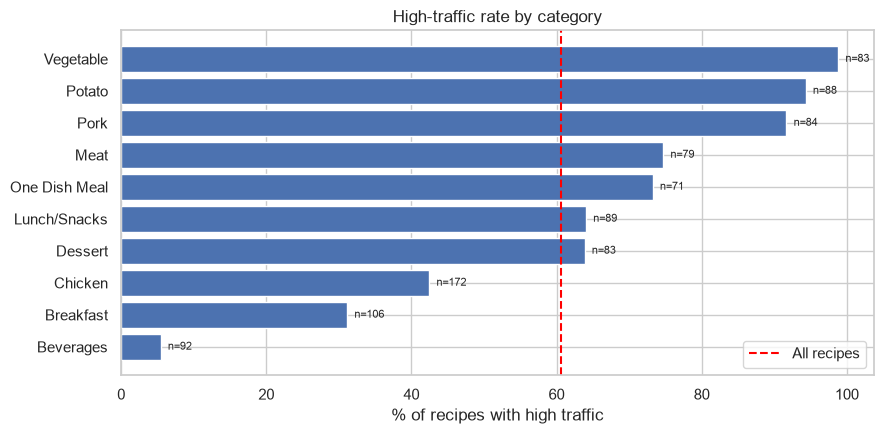

category,Beverages,Breakfast,Chicken,Dessert,Lunch/Snacks,One Dish Meal,Meat,Pork,Potato,Vegetable
high traffic %,5,31,42,64,64,73,75,92,94,99


In [5]:
by_category = recipes.groupby("category")["high_traffic"].agg(["mean", "count"]).sort_values("mean")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(by_category.index, by_category["mean"] * 100)
ax.axvline(recipes["high_traffic"].mean() * 100, color="red", linestyle="--", label="All recipes")
for i, (share, count) in enumerate(zip(by_category["mean"], by_category["count"])):
    ax.text(share * 100 + 1, i, f"n={count}", va="center", fontsize=8)
ax.set_xlabel("% of recipes with high traffic")
ax.set_title("High-traffic rate by category")
ax.legend()
plt.tight_layout()
plt.show()

(by_category["mean"] * 100).round(0).astype(int).to_frame("high traffic %").T

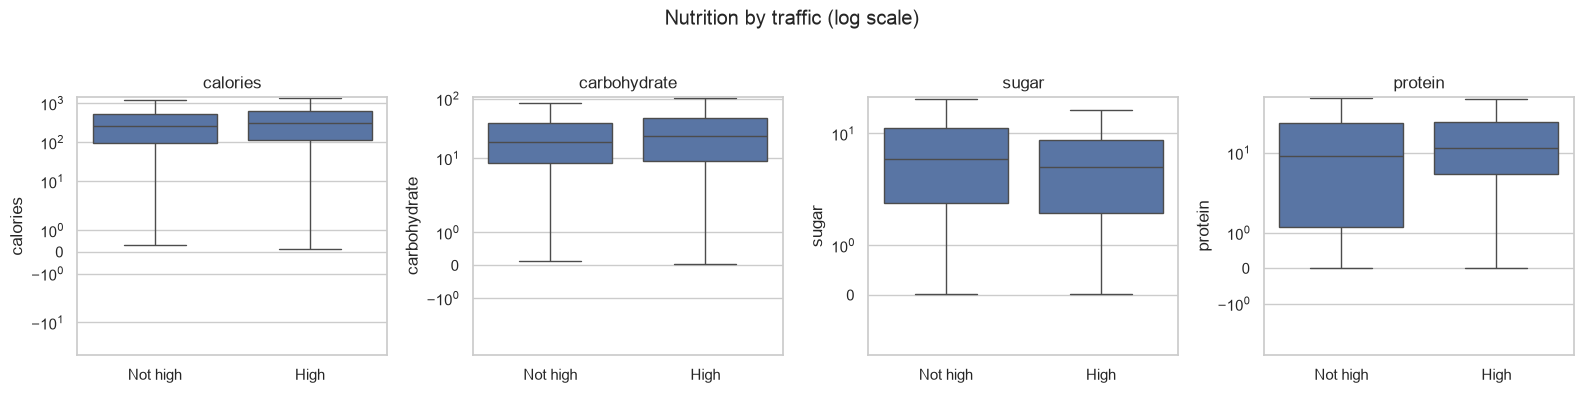

,calories,carbohydrate,sugar,protein
high_traffic,,,,
0,267.8,18.8,5.2,8.8
1,305.1,23.2,4.2,12.0


servings,1,2,4,6
mean,0.589,0.574,0.606,0.652
count,175.000,183.000,391.000,198.000


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, column in zip(axes, nutrition):
    sns.boxplot(data=recipes, x="high_traffic", y=column, ax=ax, showfliers=False)
    ax.set_yscale("symlog")
    ax.set_xticks([0, 1], labels=["Not high", "High"])
    ax.set_xlabel("")
    ax.set_title(column)
fig.suptitle("Nutrition by traffic (log scale)", y=1.03)
plt.tight_layout()
plt.show()

display(recipes.groupby("high_traffic")[nutrition].median().round(1))
recipes.groupby("servings")["high_traffic"].agg(["mean", "count"]).round(3).T

Category is the story. Vegetable, potato and pork recipes almost always produce high traffic, while beverages almost never do. The nutritional values and the number of servings barely differ between the two groups.

## 3. Models

20% of the recipes are held back as a test set. Three candidates are compared on the remaining 80% with five-fold cross-validation:

- **Category only:** logistic regression on the one-hot encoded category. This is the simplest thing that could work.
- **Logistic regression** on everything: log-transformed nutrition, servings and category.
- **Random forest** on the same features.

In [7]:
X = recipes[nutrition + ["servings", "category"]]
y = recipes["high_traffic"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

numeric = make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler())
categorical = OneHotEncoder(handle_unknown="ignore")

models = {
    "Category only": make_pipeline(
        ColumnTransformer([("category", categorical, ["category"])]),
        LogisticRegression(max_iter=1000)),
    "Logistic regression": make_pipeline(
        ColumnTransformer([("numeric", numeric, nutrition + ["servings"]), ("category", categorical, ["category"])]),
        LogisticRegression(max_iter=1000)),
    "Random forest": make_pipeline(
        ColumnTransformer([("numeric", SimpleImputer(strategy="median"), nutrition + ["servings"]),
                           ("category", categorical, ["category"])]),
        RandomForestClassifier(n_estimators=400, min_samples_leaf=5, random_state=SEED)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_probabilities, rows = {}, {}
for name, model in models.items():
    proba = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    cv_probabilities[name] = proba
    predicted = (proba >= 0.5).astype(int)
    rows[name] = {"precision": precision_score(y_train, predicted), "recall": recall_score(y_train, predicted),
                  "ROC AUC": roc_auc_score(y_train, proba)}

pd.DataFrame(rows).T.round(3)

,precision,recall,ROC AUC
Category only,0.792,0.815,0.816
Logistic regression,0.793,0.817,0.808
Random forest,0.751,0.824,0.802


## 4. Choosing a threshold for the 80% goal

A model outputs a probability, and the threshold for calling a recipe "high traffic" is a business choice. Raising it makes the model pickier: precision goes up and recall goes down. The threshold is chosen on the cross-validated training predictions, as the lowest one that gives at least 82% precision (a small margin over the goal).

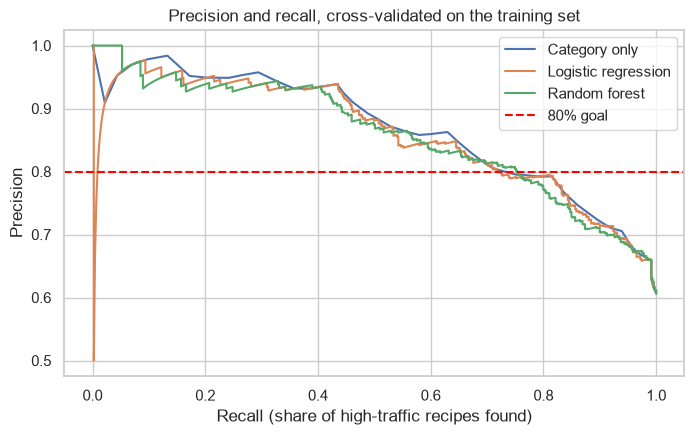

,threshold,CV precision,CV recall
Category only,0.656,0.83,0.671
Logistic regression,0.651,0.82,0.675
Random forest,0.644,0.82,0.675


In [8]:
def pick_threshold(y_true, proba, target=0.82):
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    ok = np.where(precision[:-1] >= target)[0]
    i = ok[0]
    return thresholds[i], precision[i], recall[i]


fig, ax = plt.subplots(figsize=(8, 4.5))
chosen = {}
for name, proba in cv_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_train, proba)
    ax.plot(recall, precision, label=name)
    chosen[name] = pick_threshold(y_train, proba)
ax.axhline(0.8, color="red", linestyle="--", label="80% goal")
ax.set_xlabel("Recall (share of high-traffic recipes found)")
ax.set_ylabel("Precision")
ax.set_title("Precision and recall, cross-validated on the training set")
ax.legend()
plt.show()

pd.DataFrame(chosen, index=["threshold", "CV precision", "CV recall"]).T.round(3)

## 5. Test-set result

In [9]:
test_rows = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    predicted = (proba >= chosen[name][0]).astype(int)
    test_rows[name] = {"recommended": int(predicted.sum()),
                       "of which high traffic": int((predicted & y_test.to_numpy()).sum()),
                       "precision": precision_score(y_test, predicted),
                       "recall": recall_score(y_test, predicted),
                       "ROC AUC": roc_auc_score(y_test, proba)}

print(f"Test set: {len(y_test)} recipes, {y_test.mean():.1%} high traffic")
pd.DataFrame(test_rows).T.round(3)

Test set: 190 recipes, 60.5% high traffic


,recommended,of which high traffic,precision,recall,ROC AUC
Category only,70.0,64.0,0.914,0.557,0.863
Logistic regression,72.0,66.0,0.917,0.574,0.866
Random forest,79.0,68.0,0.861,0.591,0.837


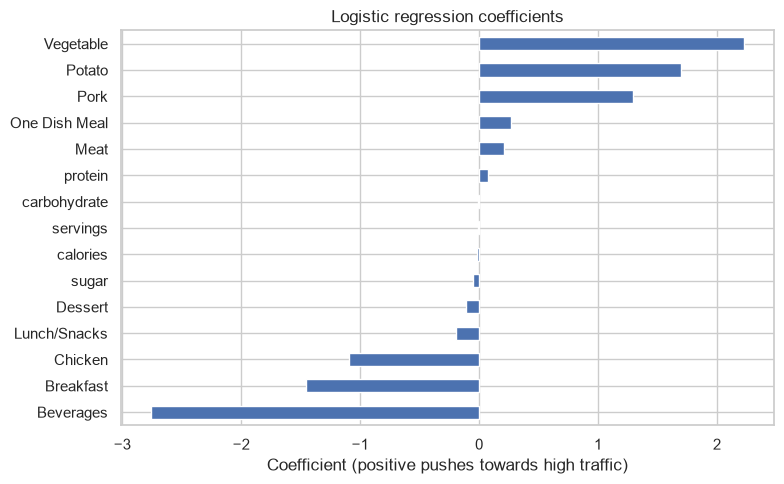

In [10]:
logreg = models["Logistic regression"]
names = logreg[0].get_feature_names_out()
coefficients = pd.Series(logreg[-1].coef_[0], index=[n.split("__")[1].replace("category_", "") for n in names]).sort_values()

ax = coefficients.plot.barh(figsize=(8, 5))
ax.set_xlabel("Coefficient (positive pushes towards high traffic)")
ax.set_title("Logistic regression coefficients")
plt.tight_layout()
plt.show()

## 6. Does this need a model at all?

The category-only model is as good as the full one, which suggests a plain rule might do: feature a recipe if its category has a high-traffic rate of at least 70% in the training data.

In [11]:
train = X_train.assign(high_traffic=y_train)
category_rates = train.groupby("category")["high_traffic"].mean()
good_categories = sorted(category_rates[category_rates >= 0.70].index)
rule = X_test["category"].isin(good_categories).astype(int)

print("Categories the rule recommends:", ", ".join(good_categories))
print(f"Recommended {rule.sum()} of {len(rule)} test recipes; "
      f"precision {precision_score(y_test, rule):.3f}, recall {recall_score(y_test, rule):.3f}")

Categories the rule recommends: Meat, One Dish Meal, Pork, Potato, Vegetable
Recommended 70 of 190 test recipes; precision 0.914, recall 0.557


## Conclusions

- **Both goals are met.** On 190 held-out recipes the logistic regression recommended 72, and 66 of them were high-traffic: 92% precision against a 61% base rate. In cross-validation, which is the more cautious estimate, the same setup gave 82% precision.
- **Category does nearly all the work.** Vegetable (99%), potato (94%) and pork (92%) recipes almost always bring high traffic; beverages (5%) almost never do. A model using category alone matches the full model, and so does a one-line rule: feature recipes from the Meat, One Dish Meal, Pork, Potato and Vegetable categories (91% precision on the test set).
- **Nutrition and servings add nothing measurable.** Calories, sugar, protein and carbohydrate are nearly identical between the two groups.
- **The price of 80% precision is recall.** The chosen threshold finds a little over half of the high-traffic recipes. Desserts and lunch/snacks are high-traffic about 64% of the time and are never recommended.

**Recommendation:** start with the category rule, because it is as accurate as the model and anyone can check it. To do better than "pick a popular category", the data needs information that varies *within* a category: preparation time, cost per serving, ingredients, the photo, the season.

Two caveats. "Not high" was inferred from blank values, so a recipe whose traffic was never recorded is counted as a miss. And every recipe here was chosen by a person to be featured, so the rates describe recipes someone already thought were worth showing.